# Conect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# Libraries

## External

In [ ]:
!pip install -q wfdb einops
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 10.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 5.0 MB/s eta 0:00:00
done!


In [ ]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras

%matplotlib inline
sns.set_theme()

## Internal

In [ ]:
import sys
sys.path.append('/content/gdrive/MyDrive/Doutorado/emg_estimator')

In [ ]:
from utils.utils import *
from dataloader.dataloader import *
from models.estimator import *
from models.data_augmentation import *

## Create paths

In [ ]:
path = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)

path2 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

## Create the datasets

### Training dataset

In [ ]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
]

In [ ]:
train_dataset_f1 = create_synced_datasets(
    path, emg_files_train_finger1, force_files_train_finger1
) # train_weights
train_dataset_f2 = create_synced_datasets(
    path, emg_files_train_finger2, force_files_train_finger2
)
train_dataset_f3 = create_synced_datasets(
    path, emg_files_train_finger3, force_files_train_finger3
)
train_dataset_f4 = create_synced_datasets(
    path, emg_files_train_finger4, force_files_train_finger4
)
train_dataset_f5 = create_synced_datasets(
    path, emg_files_train_finger5, force_files_train_finger5
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


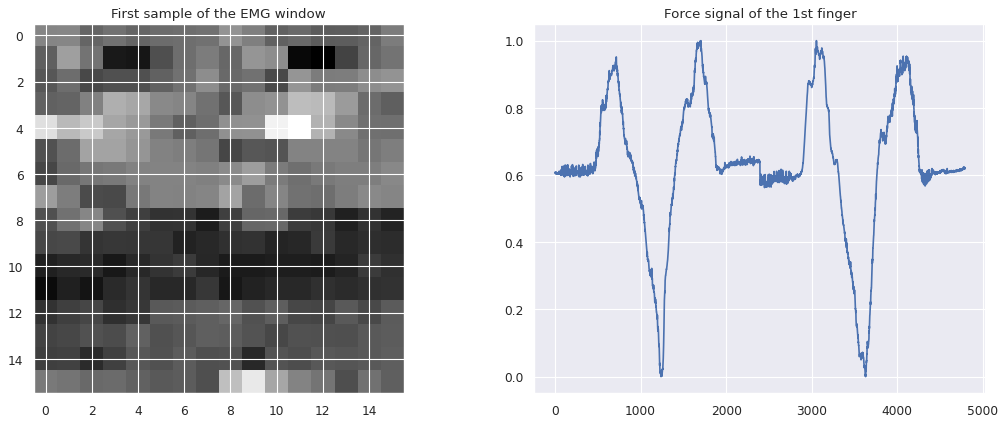

In [ ]:
# Get first window of EMG signal and force
emg_window, _ = next(iter(train_dataset_f1))
emg_window = emg_window[0]

force = []
for _, f in train_dataset_f1:
    force.append(f)
force = np.array(force)

# Plot EMG window
plt.figure(figsize=(16, 6), dpi=80)
plt.subplot(1, 2, 1)
plt.title("First sample of the EMG window")
plt.imshow(emg_window[:, :, 0], cmap='gray')

# Plot force
plt.subplot(1, 2, 2)
plt.title("Force signal of the 1st finger")
plt.plot(force[:, 0])
plt.show()

### Validation dataset

In [ ]:
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample3.hea",
]

In [ ]:
val_dataset_f1 = create_synced_datasets(
    path, emg_files_val_finger1, force_files_val_finger1
) # val_weights
val_dataset_f2 = create_synced_datasets(
    path, emg_files_val_finger2, force_files_val_finger2
)
val_dataset_f3 = create_synced_datasets(
    path, emg_files_val_finger3, force_files_val_finger3
)
val_dataset_f4 = create_synced_datasets(
    path, emg_files_val_finger4, force_files_val_finger4
)
val_dataset_f5 = create_synced_datasets(
    path, emg_files_val_finger5, force_files_val_finger5
)

### Test dataset

In [ ]:
emg_files_test_finger1 = [
    # "1dof_preprocess_finger1_sample1.hea",
    # "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_test_finger2 = [
    # "1dof_preprocess_finger2_sample1.hea",
    # "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_test_finger3 = [
    # "1dof_preprocess_finger3_sample1.hea",
    # "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_test_finger4 = [
    # "1dof_preprocess_finger4_sample1.hea",
    # "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_test_finger5 = [
    # "1dof_preprocess_finger5_sample1.hea",
    # "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_test_finger1 = [
    # "1dof_force_finger1_sample1.hea",
    # "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    # "1dof_force_finger2_sample1.hea",
    # "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_test_finger3 = [
    # "1dof_force_finger3_sample1.hea",
    # "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_test_finger4 = [
    # "1dof_force_finger4_sample1.hea",
    # "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
    # "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [ ]:
test_dataset_f1 = create_synced_datasets(
    path2, emg_files_test_finger1, force_files_test_finger1
) # , _
test_dataset_f2 = create_synced_datasets(
    path2, emg_files_test_finger2, force_files_test_finger2
)
test_dataset_f3 = create_synced_datasets(
    path2, emg_files_test_finger3, force_files_test_finger3
)
test_dataset_f4 = create_synced_datasets(
    path2, emg_files_test_finger4, force_files_test_finger4
)
test_dataset_f5 = create_synced_datasets(
    path2, emg_files_test_finger5, force_files_test_finger5
)

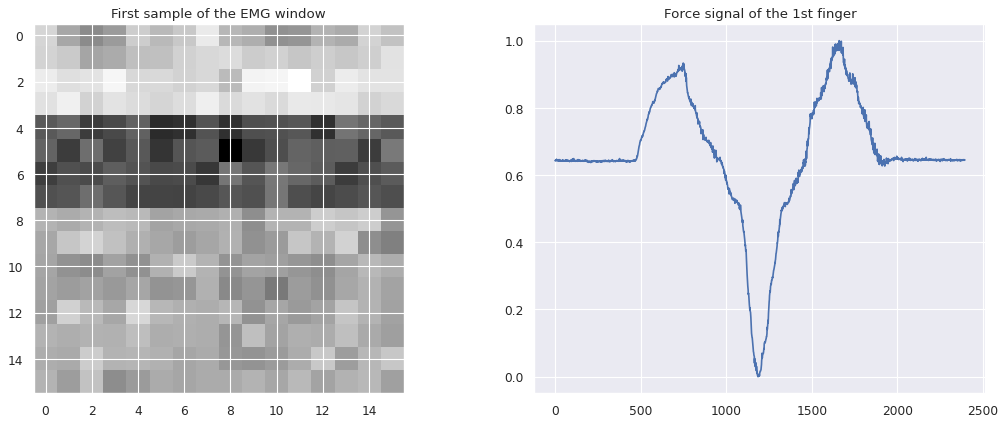

In [ ]:
# Get first window of EMG signal and force
emg_window, _ = next(iter(test_dataset_f1))
emg_window = emg_window[0]

force = []
for _, f in test_dataset_f1:
    force.append(f)
force=normalize(np.array(force), 0, 1)

# Plot EMG window
plt.figure(figsize=(16, 6), dpi=80)
plt.subplot(1, 2, 1)
plt.title("First sample of the EMG window")
plt.imshow(emg_window[:, :, 0], cmap='gray')

# Plot force
plt.subplot(1, 2, 2)
plt.title("Force signal of the 1st finger")
plt.plot(force[:, 0])
plt.show()

# Create the base model

In [ ]:
kernel_size=(18, 3, 3)
dilations=[1, 2, 4]
num_lstm_blocks = 1
input_shape = [100, 16, 16, 1] # train_dataset.element_spec[0].shape

estimator_f1 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
    # num_lstm_blocks=num_lstm_blocks
)

estimator_f1.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 dilated_conv2_plus1d (DilatedC  (None, 100, 16, 16,  4912       ['input_1[0][0]']                
 onv2Plus1D)                     16)                                                              
                                                                                                  
 dilated_conv2_plus1d_1 (Dilate  (None, 100, 16, 16,  7072       ['dilated_conv2_plus1d[0][0]']   
 dConv2Plus1D)                   16)                                                          

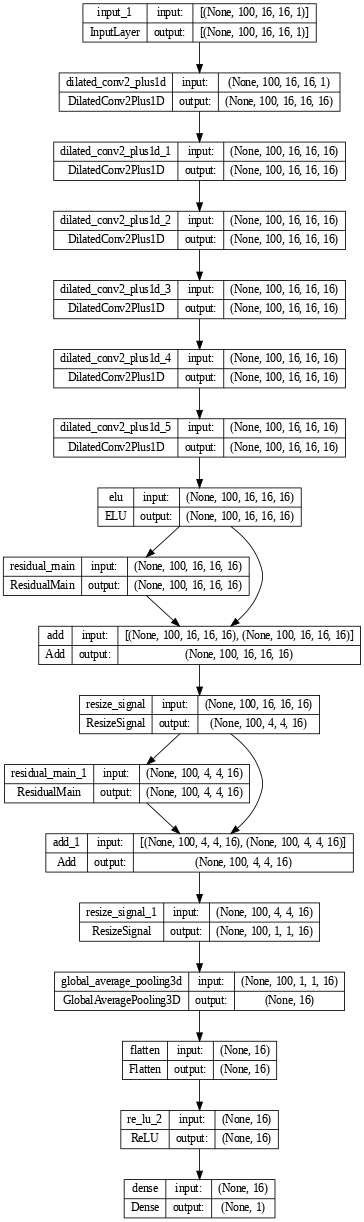

In [ ]:
keras.utils.plot_model(estimator_f1, expand_nested=True, dpi=60, show_shapes=True)
# wavenet.plot_model()

## Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_1/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_1/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=30,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

## Create the dataloader for training and validation

In [ ]:
batch_size = 8

dataset_train_f1 = train_dataset_f1.shuffle(buffer_size=len(train_dataset_f1)).batch(batch_size)
dataset_val_f1 = val_dataset_f1.batch(batch_size)

# Data augumentation

In [ ]:
#Variância do sinal de emg
variances = []
for emg, force in train_dataset_f1:
    var = tf.math.reduce_variance(emg)
    variances.append(var)
mean_variance = tf.reduce_mean(variances)
var = 0.1 * mean_variance
# desvio padrão do ruído gaussiano
std = tf.math.sqrt(var)

data_augmentation = tf.keras.Sequential([
  layers.GaussianNoise(stddev=std),
  AmplitudeScalingLayer(scale_range=(0.8, 1.2)),
  TimeShiftLayer(max_shift=0.1),
  PhaseRotationLayer(rotation_range=(-22/63, 22/63)), #pi/9
  layers.Dropout(0.2),
])

model = tf.keras.Sequential([
  data_augmentation,
  estimator_f1,
])

# Training

In [ ]:
# !train_model(dataset_train_f1, dataset_val_f1, estimator_f1)

/bin/bash: -c: line 0: syntax error near unexpected token `dataset_train_f1,'
/bin/bash: -c: line 0: `train_model(dataset_train_f1, dataset_val_f1, estimator_f1)'


In [ ]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model.compile(optimizer=optimizer, loss='mse')
# Fit data to model
history = model.fit(
    dataset_train_f1,
    epochs=100,
    validation_data=dataset_val_f1,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0297
Epoch 1: val_loss improved from inf to 0.30828, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_1/
599/599 [==============================] - 118s 177ms/step - loss: 0.0297 - val_loss: 0.3083 - lr: 0.0010
Epoch 2/100
599/599 [==============================] - ETA: 0s - loss: 0.0171
Epoch 2: val_loss improved from 0.30828 to 0.03083, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_1/
599/599 [==============================] - 108s 180ms/step - loss: 0.0171 - val_loss: 0.0308 - lr: 0.0010
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0137
Epoch 3: val_loss did not improve from 0.03083
599/599 [==============================] - 108s 181ms/step - loss: 0.0137 - val_loss: 0.7027 - lr: 0.0010
Epoch 4/100
599/599 [==============================] - ETA: 0s - loss: 0.0120
Epoch 4: val_loss did not improve

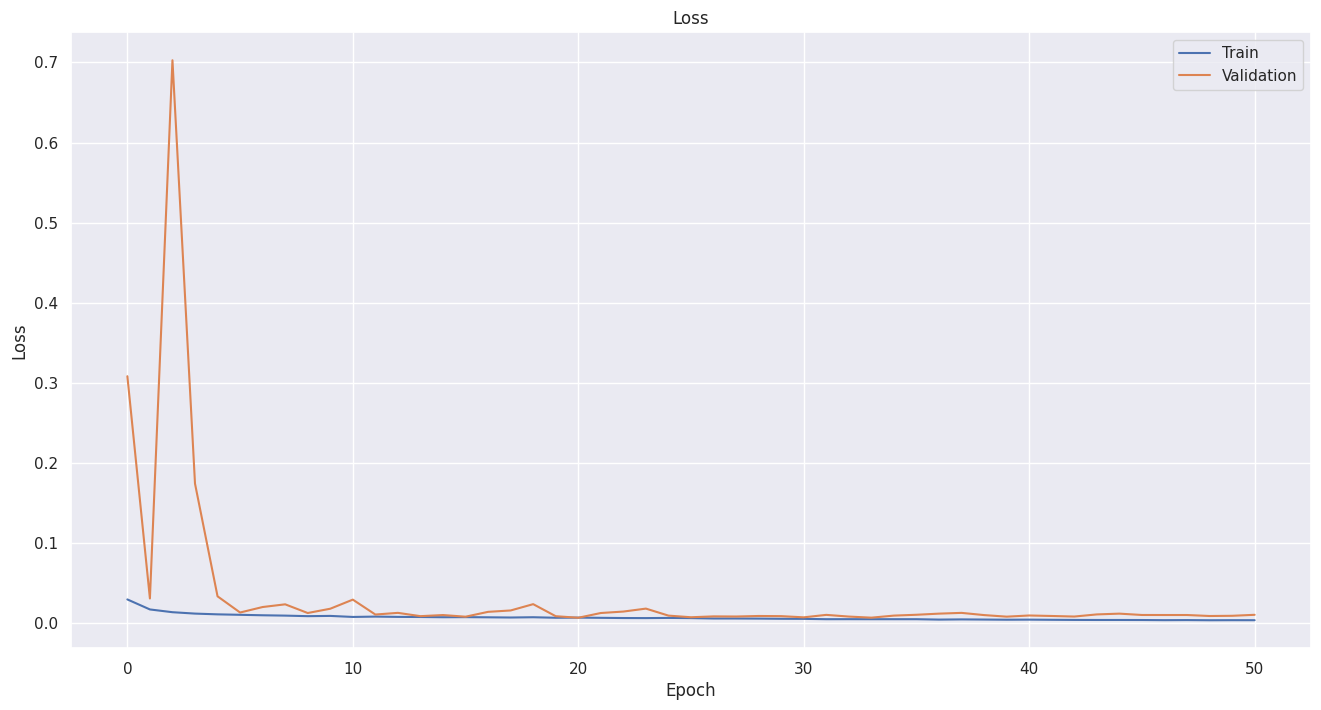

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

# Testing

In [ ]:
# Cria um objeto `tf.train.Checkpoint` com o modelo
checkpoint = tf.train.Checkpoint(model=estimator_f1)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_1/"
)

In [ ]:
emg_signal_windows, force_signal = [], []
for emg, f in train_dataset_f1.take(5000):
    emg_signal_windows.append(emg)
    force_signal.append(f)
emg_signal_windows = tf.constant(
    np.array(emg_signal_windows),
    dtype=tf.float32
)
force_signal = tf.constant(
    np.array(force_signal)
)[:,0]

print(emg_signal_windows.shape)
print(force_signal.shape)

(4790, 100, 16, 16, 1)
(4790,)


In [ ]:
predicted = estimator_f1.predict(emg_signal_windows)

150/150 [==============================] - 27s 173ms/step


In [ ]:
var_1 = tf.math.reduce_variance(emg_signal_windows)
var_1.numpy()

0.009759559

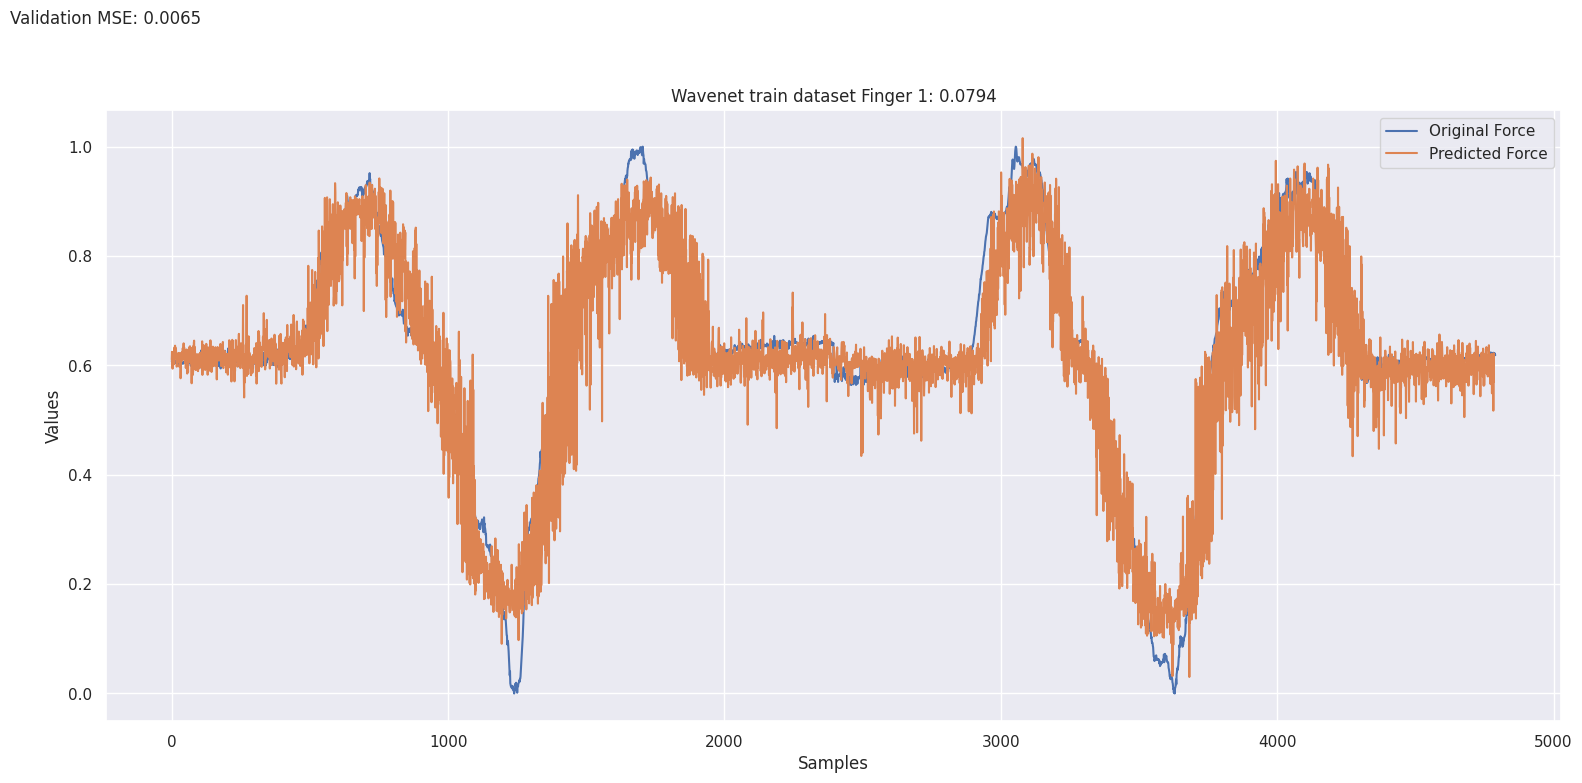

In [ ]:
# make_plot(predicted, force_signal, "Wavenet:")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 8)) #
mse_ = calc_mse(predicted, force_signal)
title = f"Wavenet train dataset Finger 1: {mse_:.4f}"
for i in range(1):
    mse = calc_mse(predicted[:,0], force_signal)
    ax.plot(force_signal, label='Original Force')
    ax.plot(predicted[:,0][5:], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
           ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {0+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")
plt.title(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f1:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = estimator_f1.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 178ms/step


In [ ]:
errors_f1 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f1)}')
print(f'variance error: {tf.math.reduce_variance(errors_f1)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.05882062390446663
variance error: 0.0018780931131914258
r^2: 0.7707994783459821


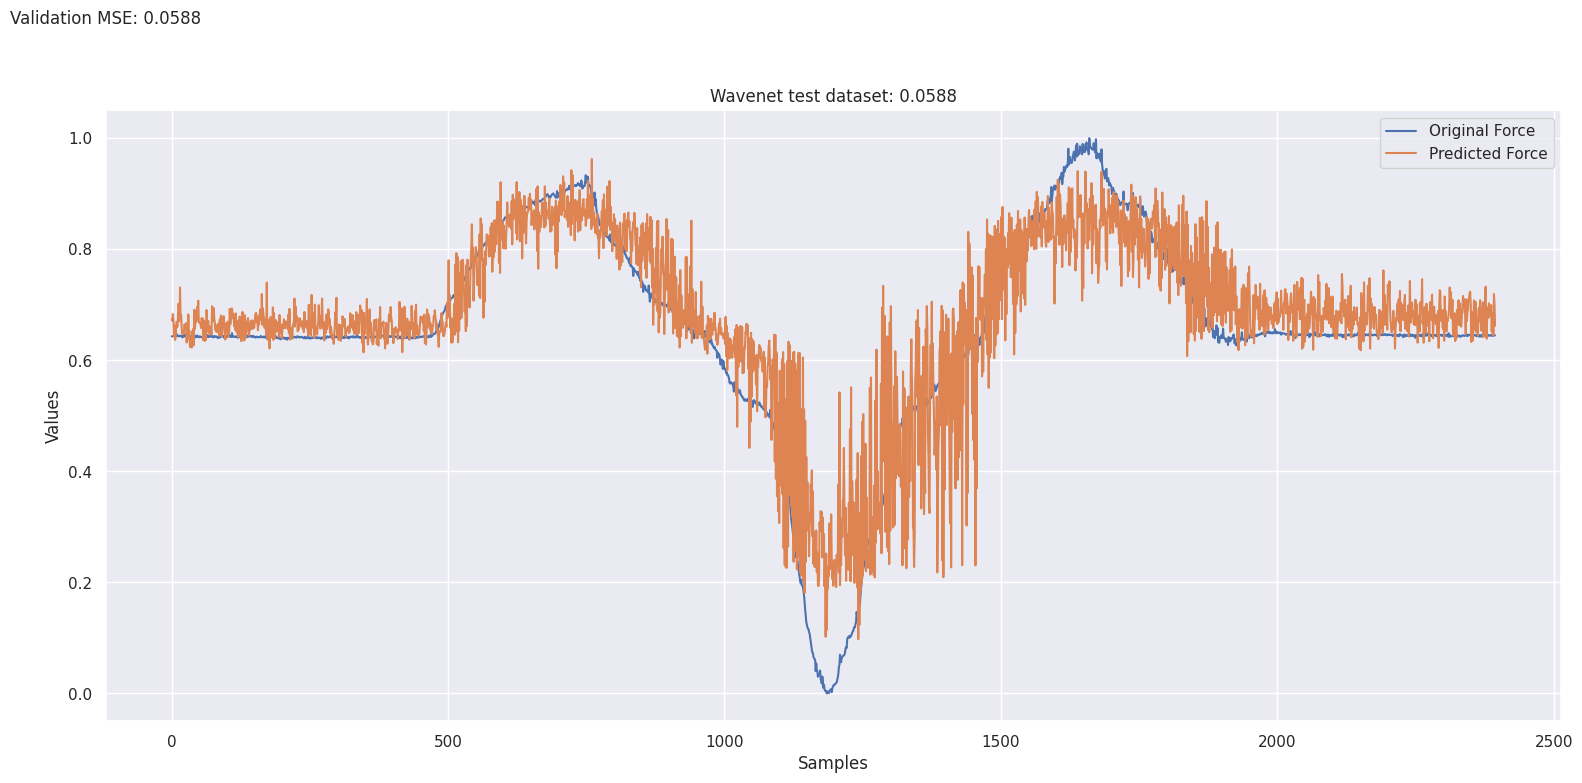

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)
fig, ax = plt.subplots(figsize=(16, 8)) # nrows=5, ncols=1,
mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"
for i in range(1):
    mse = calc_mse(predicted_test, outputs)
    ax.plot(outputs, label='Original Force')
    ax.plot(predicted_test[:,i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
        ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")
plt.title(title)
plt.tight_layout()
plt.legend()
plt.show()

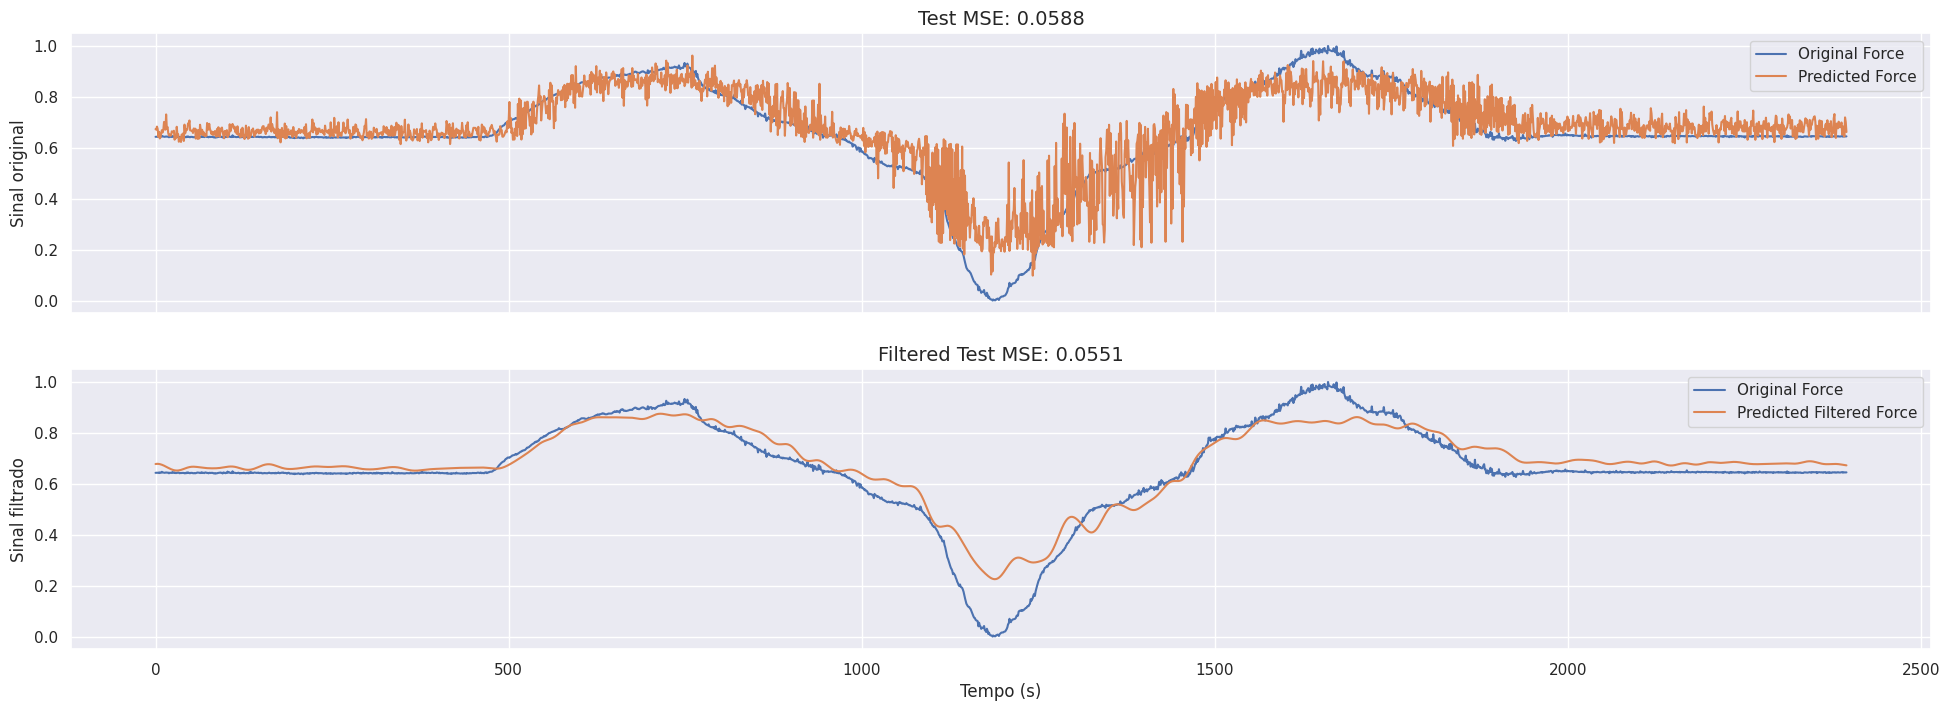

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

In [ ]:
print(f'r^2: {r2(y, outputs)}')

r^2: 0.7868826298879925


# Other fingers

## Finger 2

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/logs/model_1DoF_tensorboard/wavenet_2/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [ ]:
dataset_train_f2 = train_dataset_f2.shuffle(buffer_size=len(train_dataset_f2)).batch(batch_size)
dataset_val_f2 = val_dataset_f2.batch(batch_size)

In [ ]:
# Carregue o modelo pré-treinado
pretrained_model = estimator_f1

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f2 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
# estimator_f2 = estimator_f1

estimator_f2 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
)

model_f2 = tf.keras.Sequential([
  data_augmentation,
  estimator_f2,
])


# Compile o modelo
model_f2.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f2.fit(
    dataset_train_f2,
    validation_data=dataset_val_f2,
    epochs=100,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0417
Epoch 1: val_loss improved from inf to 0.10837, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/
599/599 [==============================] - 127s 184ms/step - loss: 0.0417 - val_loss: 0.1084 - lr: 0.0010
Epoch 2/100
599/599 [==============================] - ETA: 0s - loss: 0.0291
Epoch 2: val_loss improved from 0.10837 to 0.06286, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/
599/599 [==============================] - 109s 182ms/step - loss: 0.0291 - val_loss: 0.0629 - lr: 0.0010
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0218
Epoch 3: val_loss improved from 0.06286 to 0.02031, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/
599/599 [==============================] - 109s 182ms/step - loss: 0.0218 - val_loss: 0.0203 - lr: 0.0010
Epoch 4/100

FailedPreconditionError: ignored

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [ ]:
estimator_f2 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
)

# Cria um objeto `tf.train.Checkpoint` com o modelo
checkpoint = tf.train.Checkpoint(model=estimator_f2)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/"
)

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f2:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = estimator_f2.predict(emg_signal_windows_test)

75/75 [==============================] - 22s 179ms/step


In [ ]:
errors_f2 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f2)}')
print(f'variance error: {tf.math.reduce_variance(errors_f2)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 5.410886764526367
variance error: 0.06933824717998505
r^2: -110.27953973528209


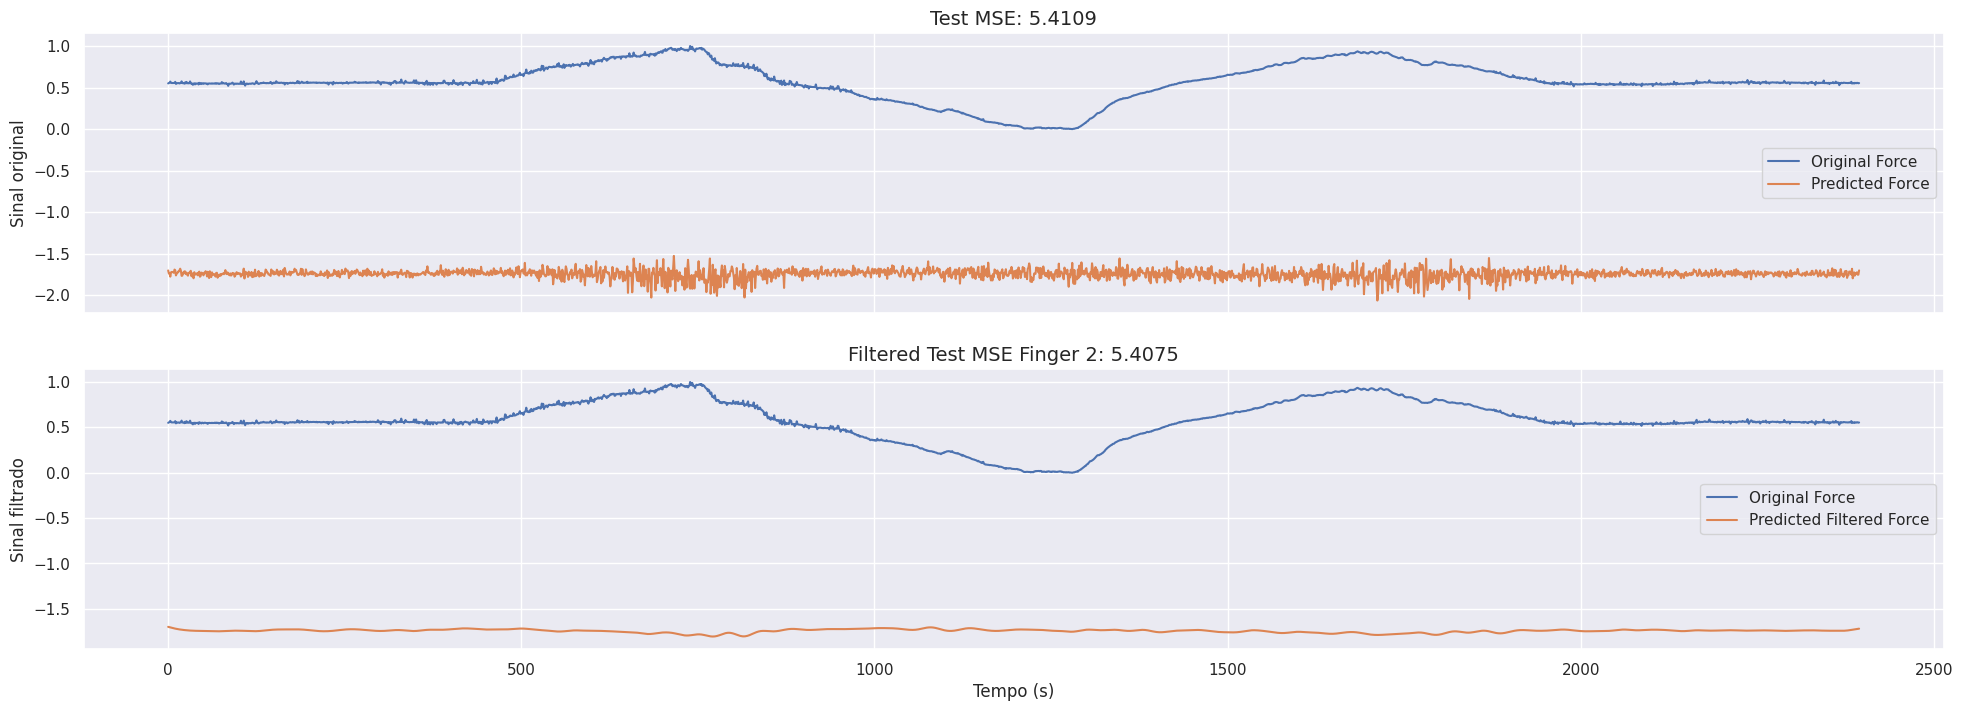

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 2: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

## Finger 3

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_3/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_3/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [ ]:
batch_size = 8
dataset_train_f3 = train_dataset_f3.shuffle(buffer_size=len(train_dataset_f3)).batch(batch_size)
dataset_val_f3 = val_dataset_f3.batch(batch_size)

In [ ]:
# Carregue o modelo pré-treinado
pretrained_model = estimator_f1

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f3 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
# estimator_f3 = estimator_f1
estimator_f3 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
)

model_f3 = tf.keras.Sequential([
  data_augmentation,
  estimator_f3,
])

# Compile o modelo
model_f3.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f3.fit(
    dataset_train_f3,
    validation_data=dataset_val_f3,
    epochs=100,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0297
Epoch 1: val_loss improved from inf to 0.08913, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_3/
599/599 [==============================] - 132s 192ms/step - loss: 0.0297 - val_loss: 0.0891 - lr: 0.0010
Epoch 2/100
599/599 [==============================] - ETA: 0s - loss: 0.0108
Epoch 2: val_loss improved from 0.08913 to 0.02517, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_3/
599/599 [==============================] - 111s 186ms/step - loss: 0.0108 - val_loss: 0.0252 - lr: 0.0010
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0099
Epoch 3: val_loss did not improve from 0.02517
599/599 [==============================] - 111s 185ms/step - loss: 0.0099 - val_loss: 0.0323 - lr: 0.0010
Epoch 4/100
599/599 [==============================] - ETA: 0s - loss: 0.0091
Epoch 4: val_loss improved from 0

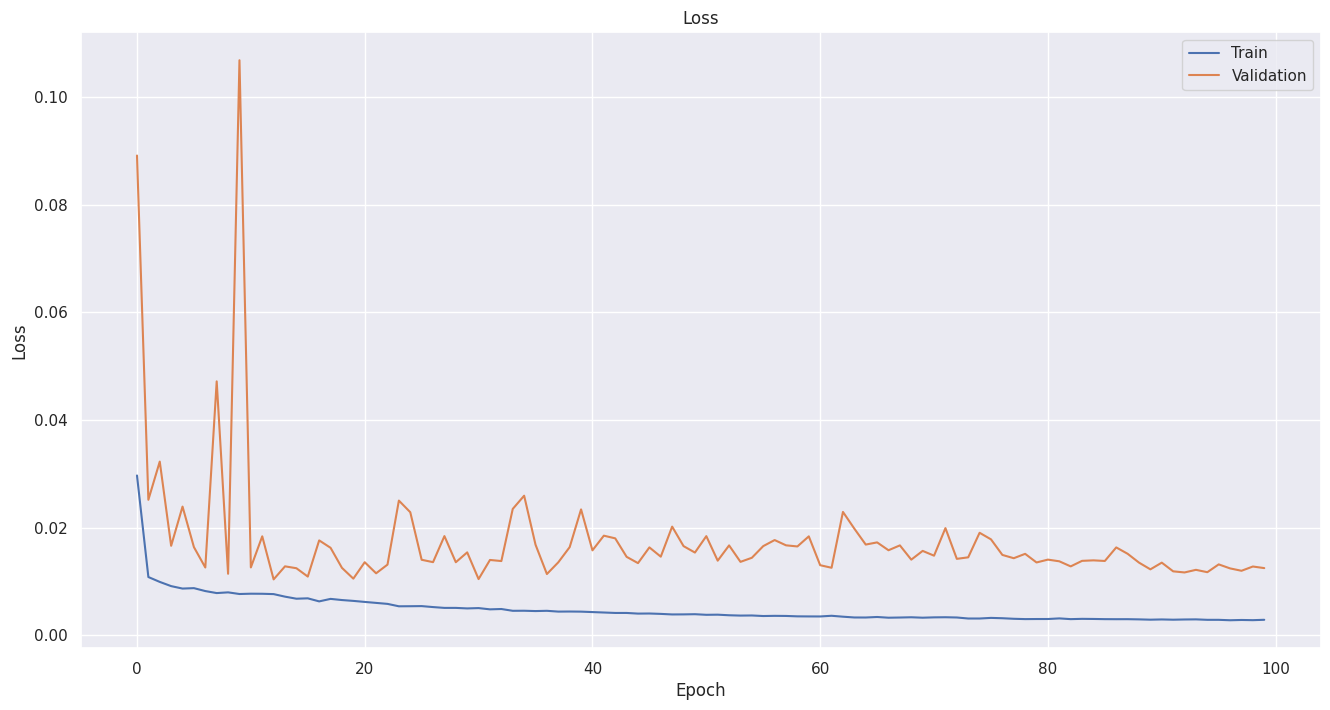

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f2:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = estimator_f3.predict(emg_signal_windows_test)

75/75 [==============================] - 14s 179ms/step


In [ ]:
errors_f3 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f3)}')
print(f'variance error: {tf.math.reduce_variance(errors_f3)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.06296684592962265
variance error: 0.0006950513343326747
r^2: 0.17480566706571088


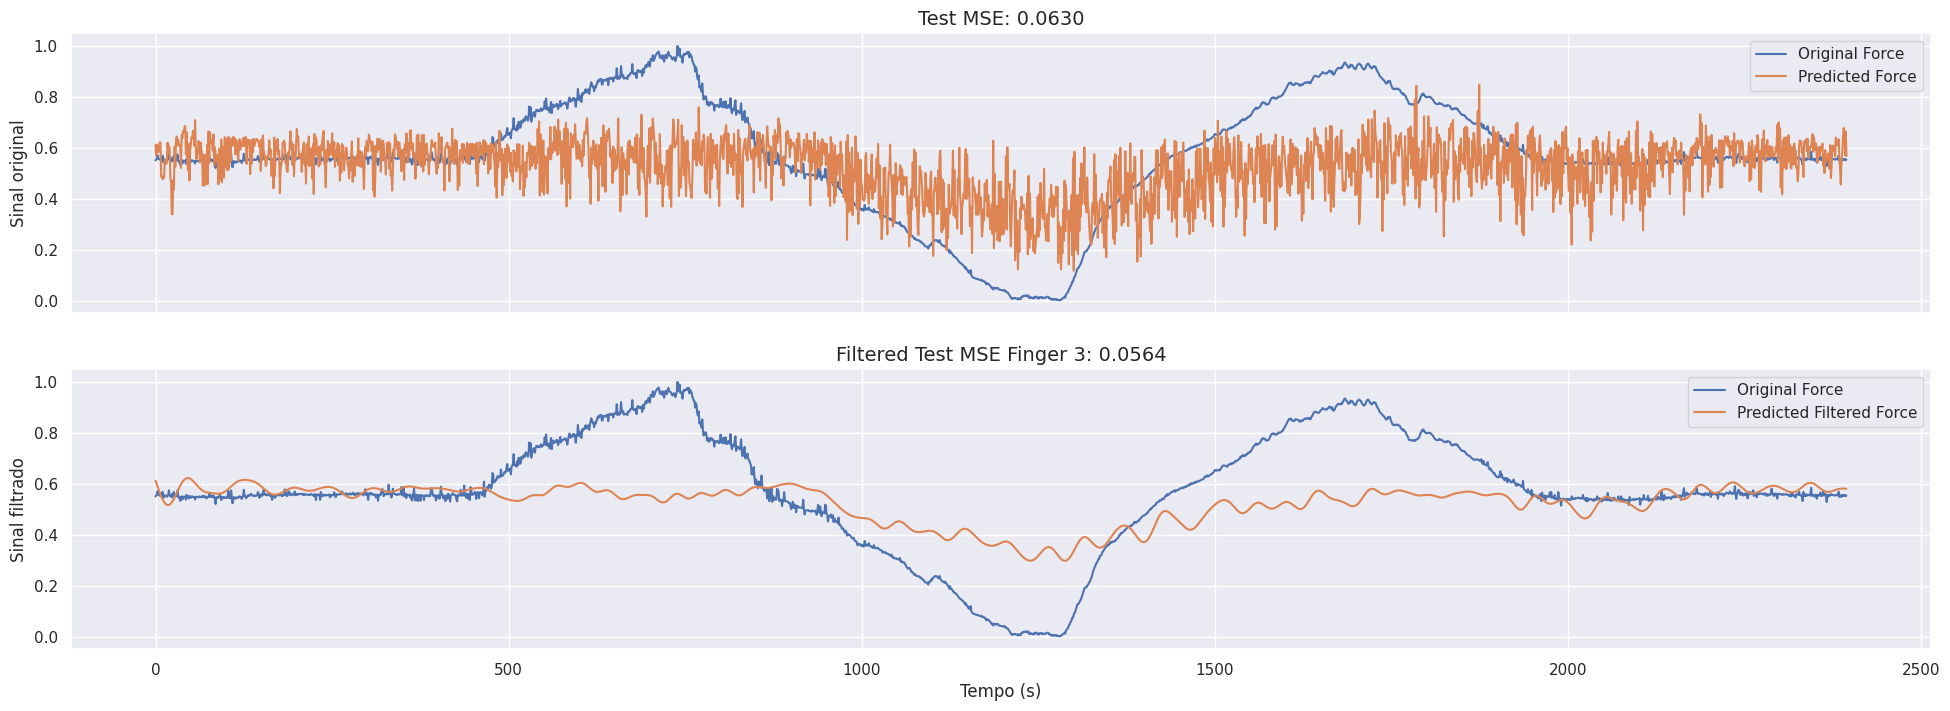

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 3: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

## Finger 4

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_4/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_4/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [ ]:
dataset_train_f4 = train_dataset_f4.shuffle(buffer_size=len(train_dataset_f4)).batch(batch_size)
dataset_val_f4 = val_dataset_f4.batch(batch_size)

In [ ]:
# Carregue o modelo pré-treinado
pretrained_model = estimator_f1

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f4 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
# estimator_f4 = estimator_f1
estimator_f4 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
)

model_f4 = tf.keras.Sequential([
  data_augmentation,
  estimator_f4,
])

# Compile o modelo
model_f4.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f3.fit(
    dataset_train_f4,
    validation_data=dataset_val_f4,
    epochs=100,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0104
Epoch 1: val_loss improved from inf to 0.01974, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_4/
599/599 [==============================] - 113s 188ms/step - loss: 0.0104 - val_loss: 0.0197 - lr: 1.0011e-04
Epoch 2/100
599/599 [==============================] - ETA: 0s - loss: 0.0077
Epoch 2: val_loss improved from 0.01974 to 0.01340, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_4/
599/599 [==============================] - 112s 187ms/step - loss: 0.0077 - val_loss: 0.0134 - lr: 1.0011e-04
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0073
Epoch 3: val_loss did not improve from 0.01340
599/599 [==============================] - 112s 186ms/step - loss: 0.0073 - val_loss: 0.0163 - lr: 1.0011e-04
Epoch 4/100
599/599 [==============================] - ETA: 0s - loss: 0.0071
Epoch 4: val_loss did

FailedPreconditionError: ignored

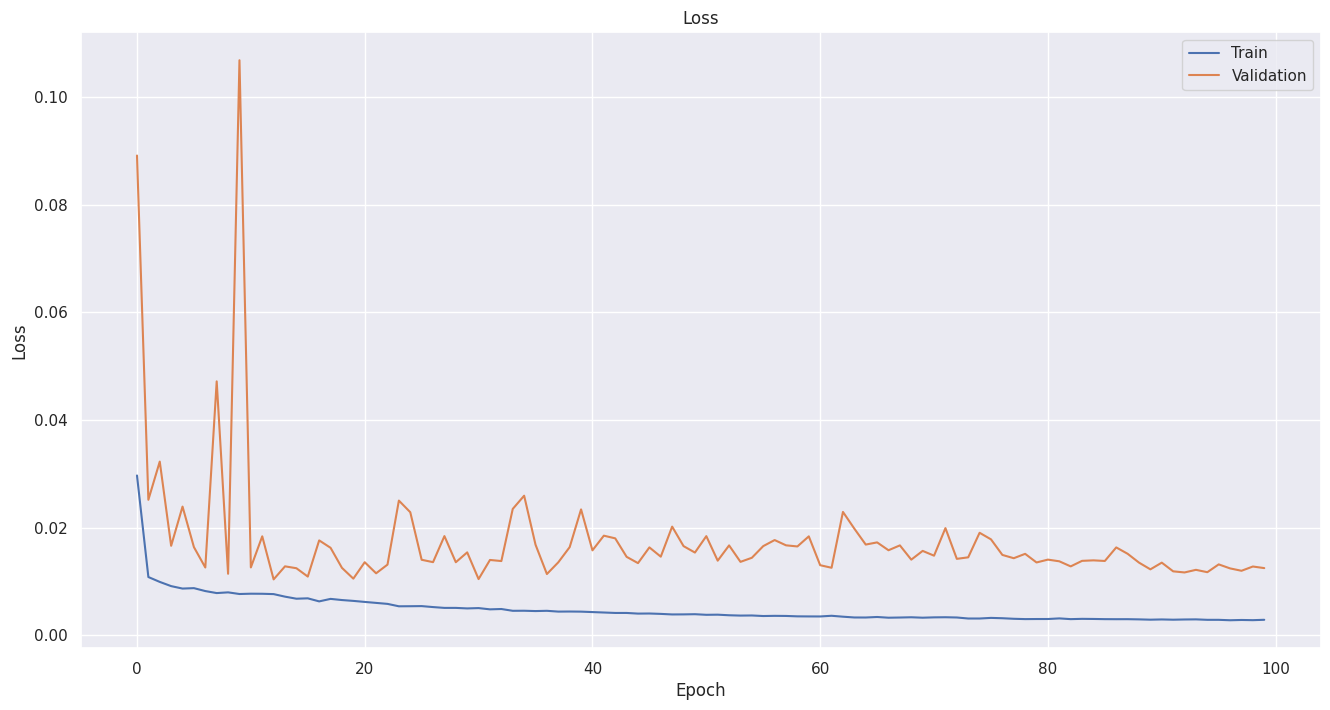

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f4:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = estimator_f4.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 171ms/step


In [ ]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.09302984923124313
variance error: 0.003704068250954151
r^2: -2.3589219946809186


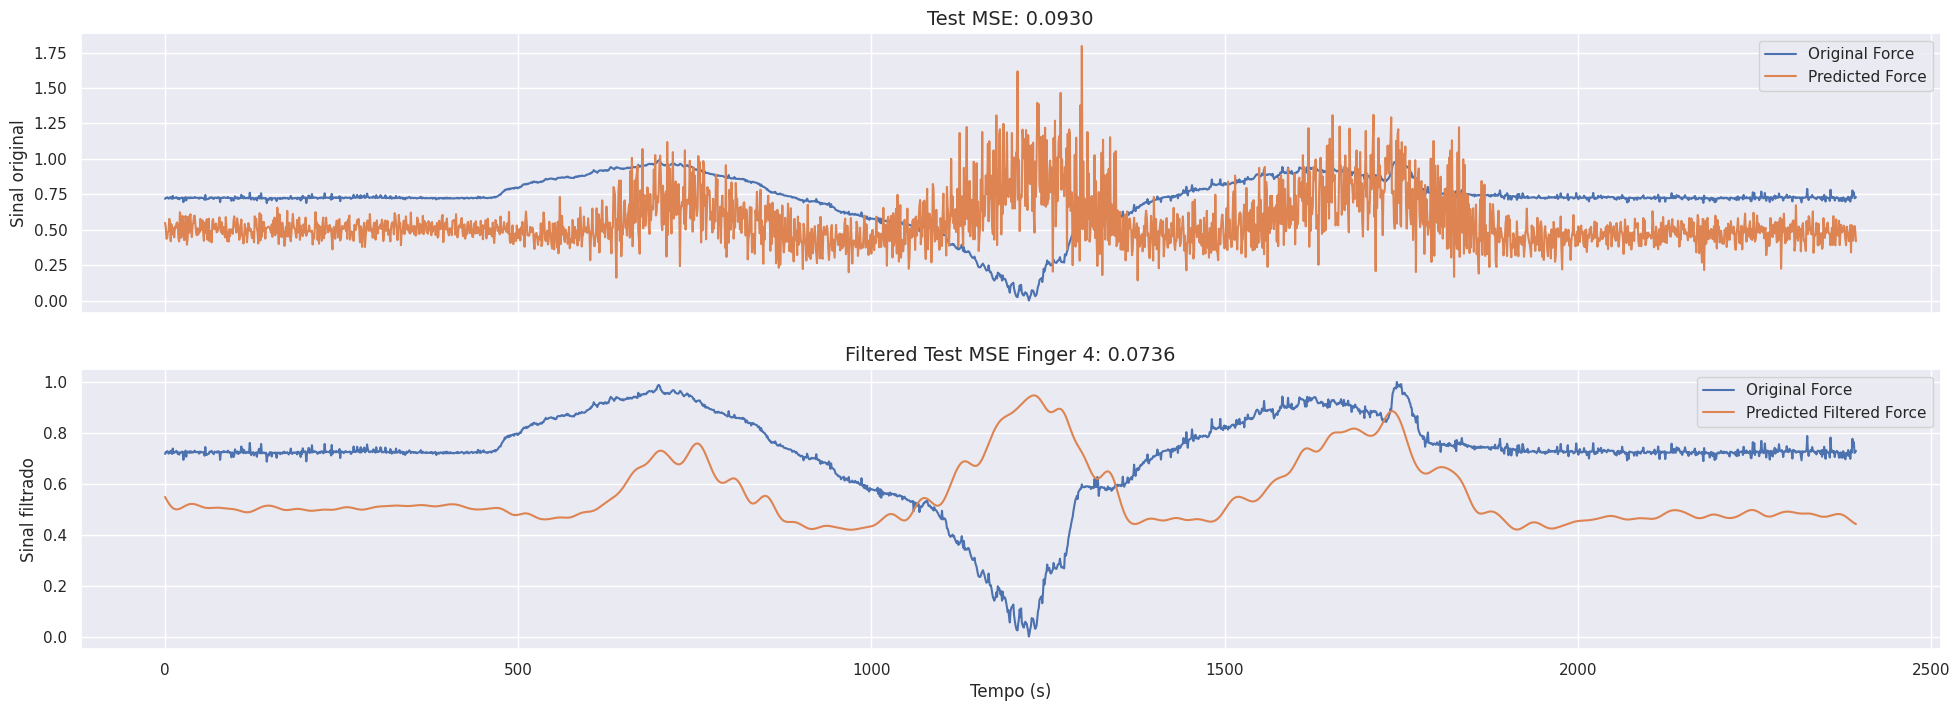

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 4: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

## Finger 5

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_5/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_5/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [ ]:
dataset_train_f5 = train_dataset_f5.shuffle(buffer_size=len(train_dataset_f5)).batch(batch_size)
dataset_val_f5 = val_dataset_f5.batch(batch_size)

In [ ]:
# Carregue o modelo pré-treinado
pretrained_model = estimator_f1

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f5 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
# estimator_f5 = estimator_f1
estimator_f5 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
)

model_f5 = tf.keras.Sequential([
  data_augmentation,
  estimator_f5,
])

# Compile o modelo
model_f5.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f5.fit(
    dataset_train_f5,
    validation_data=dataset_val_f5,
    epochs=10,
    callbacks=callback,
)

Epoch 1/10


FailedPreconditionError: ignored

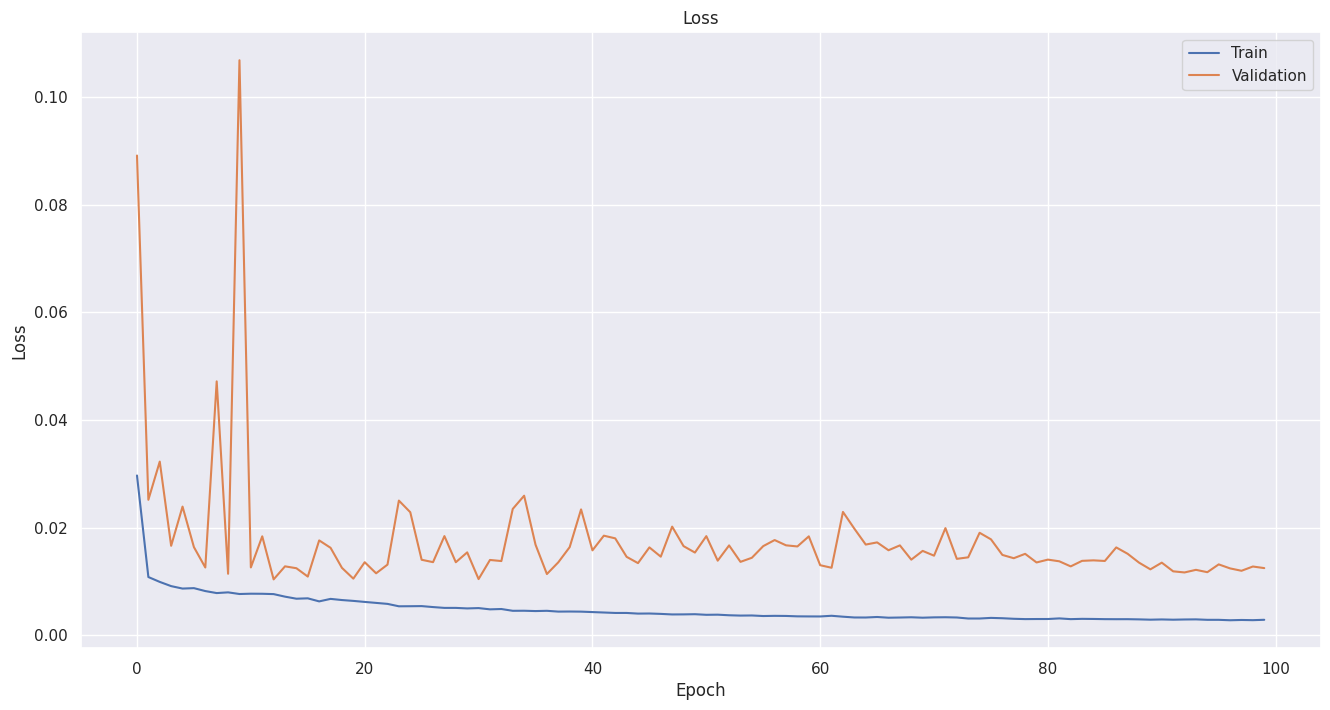

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f2:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = estimator_f5.predict(emg_signal_windows_test)

58/75 [======================>.......] - ETA: 2s

In [ ]:
errors_f5 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f5)}')
print(f'variance error: {tf.math.reduce_variance(errors_f5)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 5: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

In [ ]:
print(f'r^2: {r2(y, outputs)}')

# Mean and variance of the error

In [ ]:
# Dados dos erros e variâncias
errors = [
    tf.reduce_mean(errors_f1),
    tf.reduce_mean(errors_f2),
    tf.reduce_mean(errors_f3),
    tf.reduce_mean(errors_f4),
    tf.reduce_mean(errors_f5),
]
variances = [
    tf.math.reduce_variance(errors_f1),
    tf.math.reduce_variance(errors_f2),
    tf.math.reduce_variance(errors_f3),
    tf.math.reduce_variance(errors_f4),
    tf.math.reduce_variance(errors_f5),
]

# Create the plot
plt.figure(figsize=(10, 6))  # Define the figure size

# Plot error points
plt.scatter(range(1, 6), errors, color='blue', label='Mean Error')

# Plot variance bars
plt.errorbar(range(1, 6), errors, yerr=variances, fmt='none', ecolor='red', capsize=5, label='Error Variance')

# Plot settings
plt.xlabel('Cases')
plt.ylabel('Mean Error Value')
plt.title('Mean Error and Error Variance')
plt.legend()

# Define X-axis labels
names = [f'Finger_{i}' for i in range(1, 6)]
plt.xticks(range(1, 6), names)

# Show the plot
plt.show()